In [24]:
import pandas as pd

In [25]:
ds = pd.read_csv("uber.csv")
ds.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [26]:
ds.dropna(inplace = True)
ds.drop(columns = ["Unnamed: 0", "key"], axis = 1, inplace = True)

ds["pickup_datetime"] = pd.to_datetime(
  ds["pickup_datetime"], utc = True
)

ds["hours"] = ds["pickup_datetime"].dt.hour
ds.drop("pickup_datetime", axis = 1, inplace = True)

In [27]:
ds = ds[
  (ds["fare_amount"] > 0) &
  (ds["pickup_latitude"].between(40, 42)) &
  (ds["pickup_longitude"].between(-75, -72)) &
  (ds["dropoff_latitude"].between(40, 42)) &
  (ds["dropoff_longitude"].between(-75, -72)) &
  (ds["passenger_count"].between(1, 6))
]

<Axes: xlabel='passenger_count', ylabel='fare_amount'>

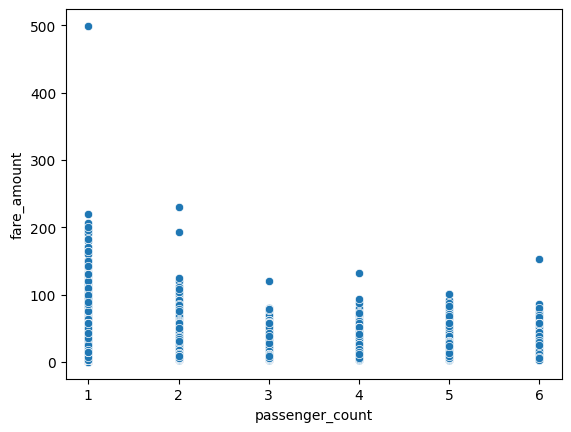

In [28]:
import seaborn as sns
sns.scatterplot(ds, y="fare_amount", x="passenger_count")

In [29]:
q1 = ds["fare_amount"].quantile(0.25)
q3 = ds["fare_amount"].quantile(0.75)
iqr = q3-q1

ds = ds[
  (ds["fare_amount"] >= q1-1.5*iqr) &
  (ds["fare_amount"] <= q3+1.5*iqr)
]

<Axes: xlabel='passenger_count', ylabel='fare_amount'>

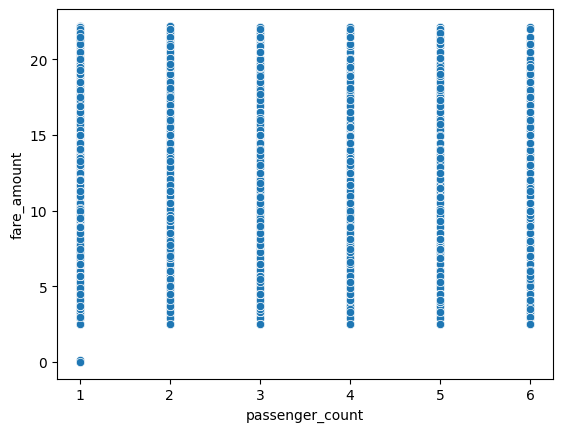

In [30]:
import seaborn as sns
sns.scatterplot(ds, y="fare_amount", x="passenger_count")